In [128]:
# %pip install mrcfile
# %pip install opencv-python
# %pip install numpy<2
# %pip install matplotlib
# %pip install scipy

1.0 0.0
3044.4294


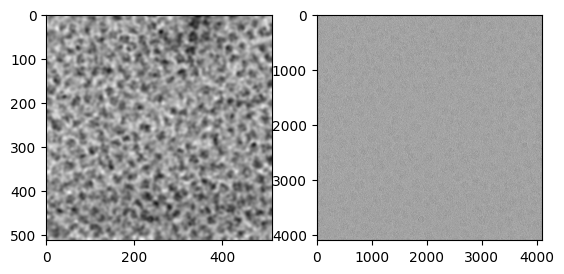

In [129]:
import mrcfile 
import matplotlib.pyplot as plt 
import cv2
import numpy as np

with mrcfile.open("image3.mrc") as mrc:
    data = mrc.data
    
test = (data-data.min())
test2 = test/test.max()
print(test2.max(), test2.min())

# re_test  = test.resize((int(test.shape[0]/4),int(test.shape[1]/4)))
re_test  = cv2.resize(test, (int(test2.shape[0]/8),int(test2.shape[1]/8)))
test_gauss = cv2.GaussianBlur(re_test, (21,21), 0) # (5x5) es el tamaño del filtro y 0 es la desviación estándar


print(test_gauss.max())

plt.subplot(1,2,1)
plt.imshow(test_gauss, cmap= "gray")
plt.subplot(1,2,2)
plt.imshow(test, cmap="gray")
plt.show()

1.0
0.0
0.56101817


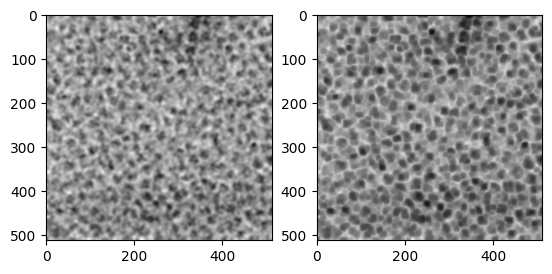

In [130]:
# mask2 = test < 0.37    
# 
# test2 = test*mask2

test_gauss_d = (test_gauss-test_gauss.min())
test_gauss_d = test_gauss_d/test_gauss_d.max()

print(test_gauss_d.max())
print(test_gauss_d.min())
print(test_gauss_d.mean())

mask1 = test_gauss > 0
test1 = test_gauss*mask1

plt.subplot(1,2,1)
plt.imshow(test1, cmap="gray")


import scipy 

min_img = scipy.ndimage.minimum_filter(test_gauss_d, size= 5)
# min_img2 = scipy.ndimage.minimum_filter(min_img, size= 5)
plt.subplot(1,2,2)
plt.imshow(min_img, cmap="gray")


In [131]:
test_gauss.shape

(512, 512)

0.0


Text(0.5, 1.0, 'mask_2')

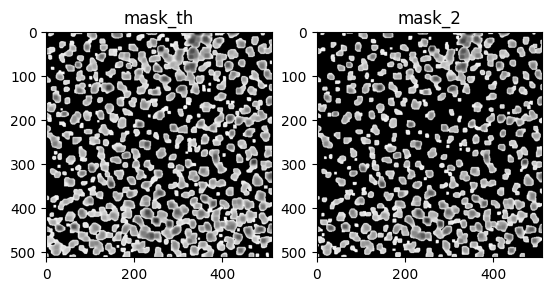

In [132]:
# alo = min_img - min_img.min()
# alo2 = alo/alo.max()
# alo2.max()
print(min_img.min())
mask_th = min_img.mean()

mask_min = min_img < mask_th
mask_min_2 = min_img < 0.45

new_min = min_img*mask_min
new_min_2 = min_img*mask_min_2

plt.subplot(1,2,1)
plt.imshow(new_min, cmap="gray")
plt.title("mask_th")
plt.subplot(1,2,2)
plt.imshow(new_min_2, cmap="gray")
plt.title("mask_2")

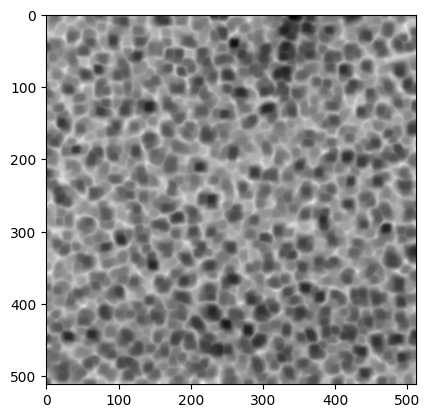

In [133]:
plt.imshow(min_img, cmap="gray")

Media de la imagen: 2954.674560546875


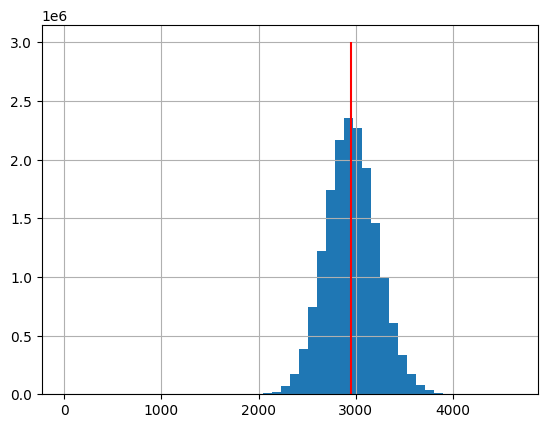

In [134]:
# Calculamos el histograma
import cv2

hist = cv2.calcHist([test_gauss], [0], None, [256], [0, 256])     # [0] son los canales, None la máscara

media_directa = np.mean(test)
print(f"Media de la imagen: {media_directa}")


# Otra forma de mostrar el histograma (solo visualización)

plt.hist(test.ravel(), bins=50)
plt.vlines(media_directa, ymin=0, ymax=3e6, color = "red")
plt.grid(True)
plt.show()


In [135]:
import pandas as pd 

data_img_clustering = []
for i in range(test1.shape[0]):
    for j in range(test1.shape[0]):
        if test1[i,j] != 0:
            data_img_clustering.append((i,j))

# df = pd.DataFrame

In [136]:
data_img_clustering

[(0, 0),
 (0, 1),
 (0, 2),
 (0, 3),
 (0, 4),
 (0, 5),
 (0, 6),
 (0, 7),
 (0, 8),
 (0, 9),
 (0, 10),
 (0, 11),
 (0, 12),
 (0, 13),
 (0, 14),
 (0, 15),
 (0, 16),
 (0, 17),
 (0, 18),
 (0, 19),
 (0, 20),
 (0, 21),
 (0, 22),
 (0, 23),
 (0, 24),
 (0, 25),
 (0, 26),
 (0, 27),
 (0, 28),
 (0, 29),
 (0, 30),
 (0, 31),
 (0, 32),
 (0, 33),
 (0, 34),
 (0, 35),
 (0, 36),
 (0, 37),
 (0, 38),
 (0, 39),
 (0, 40),
 (0, 41),
 (0, 42),
 (0, 43),
 (0, 44),
 (0, 45),
 (0, 46),
 (0, 47),
 (0, 48),
 (0, 49),
 (0, 50),
 (0, 51),
 (0, 52),
 (0, 53),
 (0, 54),
 (0, 55),
 (0, 56),
 (0, 57),
 (0, 58),
 (0, 59),
 (0, 60),
 (0, 61),
 (0, 62),
 (0, 63),
 (0, 64),
 (0, 65),
 (0, 66),
 (0, 67),
 (0, 68),
 (0, 69),
 (0, 70),
 (0, 71),
 (0, 72),
 (0, 73),
 (0, 74),
 (0, 75),
 (0, 76),
 (0, 77),
 (0, 78),
 (0, 79),
 (0, 80),
 (0, 81),
 (0, 82),
 (0, 83),
 (0, 84),
 (0, 85),
 (0, 86),
 (0, 87),
 (0, 88),
 (0, 89),
 (0, 90),
 (0, 91),
 (0, 92),
 (0, 93),
 (0, 94),
 (0, 95),
 (0, 96),
 (0, 97),
 (0, 98),
 (0, 99),
 (0, 100),

In [137]:
stop

NameError: name 'stop' is not defined

### Affinity Propagation / K-means

In [ ]:
from sklearn.cluster import AffinityPropagation
n = 0 # sector 
X = data_img_clustering
X
X_tests = X[int(n*len(X)/16):int((n+1)*len(X)/16)]

clustering = AffinityPropagation()

cosas = clustering.fit(X_tests)

# clustering.predict()

KeyboardInterrupt: 

In [ ]:
from sklearn.cluster import KMeans


kmeans = KMeans(n_clusters=16*16).fit(X)

# info = 

In [ ]:
labels = kmeans.labels_

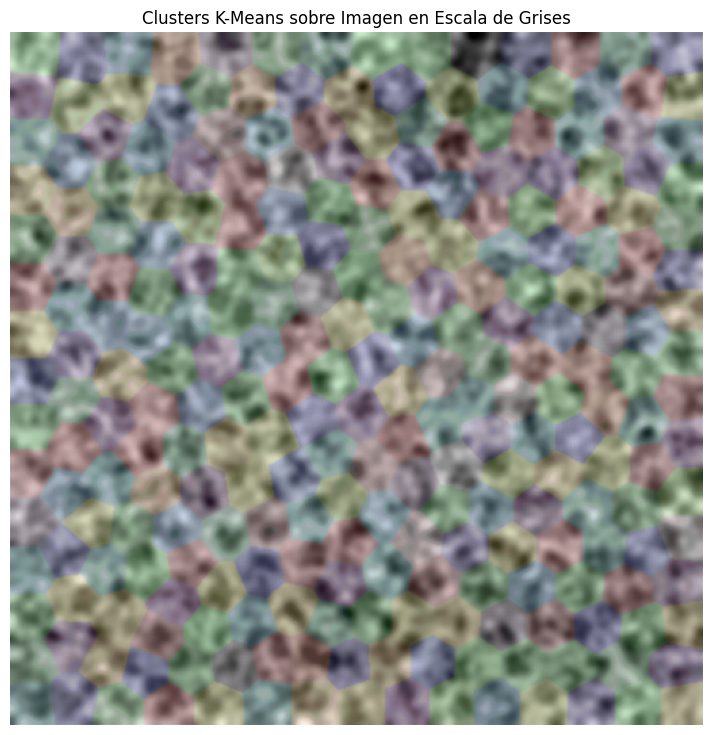

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import KMeans
s = 64

kmeans = KMeans(n_clusters=s*s).fit(X)
# 1. Separar las coordenadas x e y desde la lista de tuplas
coords = np.array(data_img_clustering)
x = coords[:, 0]
y = coords[:, 1]

# 2. Configurar el gráfico
plt.figure(figsize=(9, 9))

# Mostrar la imagen base en escala de grises
# (ajusta el nombre de tu variable si no se llama 'imagen')
plt.imshow(test_gauss, cmap="gray")

# Superponer los puntos con colores por cluster
plt.scatter(
    x,
    y,
    c=labels,
    cmap="nipy_spectral",  # Paleta con alta variación para 256 grupos
    s=3,  # Tamaño de los puntos
    alpha=0.015,
)

plt.title("Clusters K-Means sobre Imagen en Escala de Grises")
plt.axis("off")  # Oculta los ejes numéricos
plt.show()